In [3]:
import os
import numpy as np
from PIL import Image
import random

DATA_DIR = r"C:\Users\Роман\Desktop\pic"
IMG_SIZE = 28
SUPPORTED_EXT = (".png", ".jpg", ".jpeg", ".bmp", ".pgm", ".gif", ".tif", ".tiff", ".webp")

FOLDER_TO_CHAR = {
    "0": "0", "1": "1", "2": "2", "3": "3", "4": "4",
    "5": "5", "6": "6", "7": "7", "8": "8", "9": "9",
    "+": "+", "-": "-", "(": "(", ")": ")",
    ",": ",", "X": "X", "y": "y",
    "h": "h", "t": "t", "w": "w",
    "times": "×",
}

X_pool = []
y_pool = []

for folder in sorted(os.listdir(DATA_DIR)):
    folder_path = os.path.join(DATA_DIR, folder)
    if not os.path.isdir(folder_path):
        continue
    if folder not in FOLDER_TO_CHAR:
        print(f"⚠ Пропускаю неизвестную папку: {folder!r}")
        continue

    char = FOLDER_TO_CHAR[folder]
    count = 0
    for fname in os.listdir(folder_path):
        if not fname.lower().endswith(SUPPORTED_EXT):
            continue
        fpath = os.path.join(folder_path, fname)
        try:
            img = Image.open(fpath).convert("L")
            img = img.resize((IMG_SIZE, IMG_SIZE))
            arr = np.array(img, dtype=np.float32) / 255.0
            X_pool.append(arr)
            y_pool.append(char)
            count += 1
        except Exception as e:
            print(f"  Не прочитал {fname}: {e}")
    print(f"Папка {folder!r:8} -> символ {char!r}: {count} изображений")

X_pool = np.array(X_pool)
y_pool = np.array(y_pool)
print("\nВсего изображений:", len(X_pool))
print("Форма:", X_pool.shape)
print("Классы:", sorted(set(y_pool)))

Папка '('      -> символ '(': 14294 изображений
Папка ')'      -> символ ')': 14355 изображений
Папка '+'      -> символ '+': 25112 изображений
Папка ','      -> символ ',': 1906 изображений
Папка '-'      -> символ '-': 33997 изображений
Папка '0'      -> символ '0': 6914 изображений
Папка '1'      -> символ '1': 26520 изображений
Папка '2'      -> символ '2': 26141 изображений
Папка '3'      -> символ '3': 10909 изображений
Папка '4'      -> символ '4': 7396 изображений
Папка '5'      -> символ '5': 3545 изображений
Папка '6'      -> символ '6': 3118 изображений
Папка '7'      -> символ '7': 2909 изображений
Папка '8'      -> символ '8': 3068 изображений
Папка '9'      -> символ '9': 628 изображений
Папка 'X'      -> символ 'X': 26594 изображений
Папка 'h'      -> символ 'h': 1464 изображений
Папка 't'      -> символ 't': 3274 изображений
Папка 'times'  -> символ '×': 3251 изображений
Папка 'w'      -> символ 'w': 556 изображений
Папка 'y'      -> символ 'y': 9340 изображений

Всего 

In [4]:
import numpy as np
import random

np.random.seed(42)
random.seed(42)

from sklearn.model_selection import train_test_split


X_flat = X_pool.reshape(len(X_pool), -1)
print("X_flat:", X_flat.shape, X_flat.dtype)  
print("ОЗУ под X_flat, МБ:", X_flat.nbytes / 1024**2)

X_train, X_test, y_train, y_test = train_test_split(
    X_flat, y_pool,
    test_size=0.25,
    random_state=42,
    stratify=y_pool,         
)
print("Обучающих:", len(X_train))
print("Тестовых: ", len(X_test))
print("Форма X_train:", X_train.shape)
print("Форма X_test: ", X_test.shape)

X_flat: (225291, 784) float32
ОЗУ под X_flat, МБ: 673.7828979492188
Обучающих: 168968
Тестовых:  56323
Форма X_train: (168968, 784)
Форма X_test:  (56323, 784)


In [6]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

k_values = [1,2, 3,4, 5]        
accuracies = []

for k in k_values:
    print(f"\n>>> k={k}: обучение...")
    clf = KNeighborsClassifier(n_neighbors=k, weights="distance", n_jobs=-1)
    clf.fit(X_train, y_train)
    print(f"    k={k}: предсказание на {len(X_test)} тестовых...")
    y_pred = clf.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    accuracies.append(acc)
    print(f"    k={k:2d}  accuracy={acc:.4f}")

best_k = k_values[int(np.argmax(accuracies))]
print(f"\nОптимальное k = {best_k}, accuracy = {max(accuracies):.4f}")


>>> k=1: обучение...
    k=1: предсказание на 56323 тестовых...
    k= 1  accuracy=0.9923

>>> k=2: обучение...
    k=2: предсказание на 56323 тестовых...
    k= 2  accuracy=0.9919

>>> k=3: обучение...
    k=3: предсказание на 56323 тестовых...
    k= 3  accuracy=0.9919

>>> k=4: обучение...
    k=4: предсказание на 56323 тестовых...
    k= 4  accuracy=0.9915

>>> k=5: обучение...
    k=5: предсказание на 56323 тестовых...
    k= 5  accuracy=0.9915

Оптимальное k = 1, accuracy = 0.9923


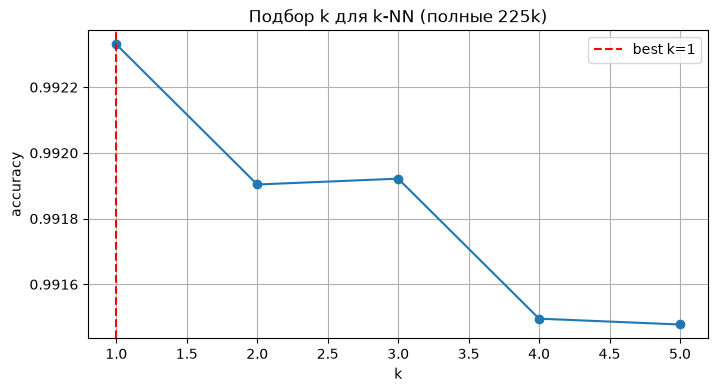

In [13]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 4))
plt.plot(k_values, accuracies, marker="o")
plt.axvline(best_k, color="red", ls="--", label=f"best k={best_k}")
plt.xlabel("k")
plt.ylabel("accuracy")
plt.title("Подбор k для k-NN (полные 225k)")
plt.grid(True)
plt.legend()
plt.show()

In [10]:
from sklearn.metrics import classification_report, confusion_matrix

classifier = KNeighborsClassifier(n_neighbors=best_k, weights="distance", n_jobs=-1)
classifier.fit(X_train, y_train)

print("Предсказание на тесте...")
y_pred = classifier.predict(X_test)

print("\naccuracy:", accuracy_score(y_test, y_pred))
print("\nclassification_report:")
print(classification_report(y_test, y_pred, zero_division=0))

Предсказание на тесте...

accuracy: 0.9923299540152336

classification_report:
              precision    recall  f1-score   support

           (       0.98      1.00      0.99      3574
           )       0.99      1.00      1.00      3589
           +       1.00      0.99      0.99      6278
           ,       0.91      0.90      0.91       476
           -       0.99      1.00      1.00      8499
           0       1.00      1.00      1.00      1729
           1       0.99      1.00      0.99      6630
           2       0.99      1.00      1.00      6535
           3       0.99      0.99      0.99      2727
           4       1.00      0.99      0.99      1849
           5       0.99      0.98      0.98       886
           6       1.00      0.98      0.99       779
           7       1.00      0.98      0.99       727
           8       1.00      0.96      0.98       767
           9       1.00      0.54      0.70       157
           X       1.00      0.99      1.00      6649
  

In [14]:
ALL_CHARS = sorted(set(y_pool))
print("Доступные символы:", ALL_CHARS)

def generate_expression():
    
    a = str(np.random.randint(0, 10))
    b = str(np.random.randint(0, 10))
    op = np.random.choice(["+", "-", "×"])
    kind = np.random.rand()

    if kind < 0.25:
        # (3+5)
        return f"({a}{op}{b})"
    if kind < 0.45:
        # X+3
        return f"X{op}{a}"
    if kind < 0.65:
        # y-7
        return f"y{op}{a}"
    if kind < 0.85:
        # h(t+2)
        return f"h({a}{op}{b})"
    # 3+5
    return f"{a}{op}{b}"

def generate_random_text(min_len=5, max_len=12):
   
    n = np.random.randint(min_len, max_len + 1)
    return "".join(np.random.choice(ALL_CHARS) for _ in range(n))

def text_to_images(text):
    
    images = []
    for ch in text:
        if ch == " ":
            images.append(None)
            continue
        candidates = np.where(y_pool == ch)[0]
        if len(candidates) == 0:
            print(f"⚠ Символ {ch!r} отсутствует в пуле — пропускаю")
            continue
        idx = np.random.choice(candidates)
        images.append(X_pool[idx].copy())
    return images


texts = [generate_expression() for _ in range(30)]
image_lists = [text_to_images(t) for t in texts]

print("\nПримеры сгенерированных выражений:")
for t in texts[:10]:
    print(repr(t))


Доступные символы: [np.str_('('), np.str_(')'), np.str_('+'), np.str_(','), np.str_('-'), np.str_('0'), np.str_('1'), np.str_('2'), np.str_('3'), np.str_('4'), np.str_('5'), np.str_('6'), np.str_('7'), np.str_('8'), np.str_('9'), np.str_('X'), np.str_('h'), np.str_('t'), np.str_('w'), np.str_('y'), np.str_('×')]

Примеры сгенерированных выражений:
'(6+3)'
'X×7'
'y+6'
'(7-2)'
'(7-5)'
'y-4'
'y×8'
'9×2'
'y+8'
'(4×8)'


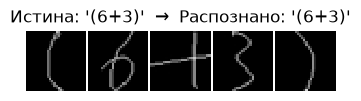

Истина: '(6+3)'
Pred:   '(6+3)'
------------------------------------------------------------


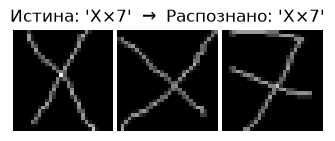

Истина: 'X×7'
Pred:   'X×7'
------------------------------------------------------------


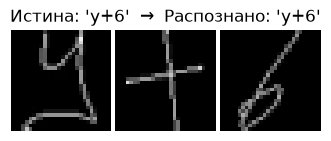

Истина: 'y+6'
Pred:   'y+6'
------------------------------------------------------------


In [15]:
def render_sequence(image_list, title=""):
    
    gap = np.zeros((IMG_SIZE, 1))
    parts = []
    for im in image_list:
        if im is None:
           
            parts.append(np.zeros((IMG_SIZE, IMG_SIZE // 2)))
        else:
            parts.append(im)
        parts.append(gap)
    if parts:
        parts.pop()
    strip = np.hstack(parts) if parts else np.zeros((IMG_SIZE, IMG_SIZE))
    plt.figure(figsize=(max(4, len(strip) / 8), 2))
    plt.imshow(strip, cmap="gray_r", interpolation="nearest")
    plt.axis("off")
    plt.title(title)
    plt.show()

def recognize_sequence(image_list, classifier):
    chars = []
    for im in image_list:
        if im is None:
            chars.append(" ")
        else:
            vec = im.reshape(1, -1)
            pred = classifier.predict(vec)[0]
            chars.append(str(pred))
    return "".join(chars)

for i in range(3):
    true_text = texts[i]
    pred_text = recognize_sequence(image_lists[i], classifier)
    render_sequence(
        image_lists[i],
        title=f"Истина: '{true_text}'  →  Распознано: '{pred_text}'",
    )
    print(f"Истина: {true_text!r}")
    print(f"Pred:   {pred_text!r}")
    print("-" * 60)

In [16]:
def sequence_accuracy(texts, image_lists, classifier):

    correct = total = 0
    errors = []
    for text, imgs in zip(texts, image_lists):
        pred = recognize_sequence(imgs, classifier)
        for a, b in zip(text, pred):
            total += 1
            if a == b:
                correct += 1
            else:
                errors.append((a, b, text, pred))
        total += abs(len(text) - len(pred))
    acc = correct / total if total else 0.0
    return acc, errors

acc_seq, errors = sequence_accuracy(texts, image_lists, classifier)
print(f"Посимвольная accuracy на {len(texts)} выражениях: {acc_seq:.4f}")
print(f"Всего ошибок: {len(errors)}")

if errors:
    print("\nПримеры ошибок (истина → предсказание):")
    seen = set()
    for a, b, t, p in errors[:20]:
        key = (a, b)
        if key in seen:
            continue
        seen.add(key)
        print(f"  '{a}' → '{b}'   (в строке: {t!r} → {p!r})")

Посимвольная accuracy на 30 выражениях: 0.9828
Всего ошибок: 2

Примеры ошибок (истина → предсказание):
  '9' → '3'   (в строке: 'h(4×9)' → 'h(4×3)')
  'X' → '1'   (в строке: 'X-6' → '1-6')
